# Load libraries

In [37]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

In [38]:
def get_unique_couplings(data):
    unique_elements = set(data)
    unique_elements_list = sorted(unique_elements)
    final_list = [round(float(elem), 1) for elem in unique_elements_list]
    print(final_list)
    return final_list

def compare_distributions(variable, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            data = variable[indices]
            plt.hist(data, bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=True, range=x_range)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        plt.show()

# Read the inputs.

In [40]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('../../H5Files/Mass_Inference_posW.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['hmass'][:]
coupling_values = get_unique_couplings(couplings_array)
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


# Get 100k of each coupling for training
# Set random seed for reproducibility
np.random.seed(42)
for coupling in coupling_values:
    indices = indices_per_coupling[coupling]
    if len(indices) > 300000:
        selected_indices = np.random.choice(indices.flatten(), 300000, replace=False)
    else:
        selected_indices = indices.flatten()
    indices_per_coupling[coupling] = selected_indices
print(f'Total training events: {sum(len(indices) for indices in indices_per_coupling.values())}')

training_indices = np.concatenate(list(indices_per_coupling.values()))

BG events =  3981348
Signal events =  3415576
[0.0, 600.0, 650.0, 700.0, 800.0, 870.0, 900.0, 1000.0]
Coupling 0.0: 3981348 events
Coupling 600.0: 470922 events
Coupling 650.0: 485427 events
Coupling 700.0: 489490 events
Coupling 800.0: 491980 events
Coupling 870.0: 492635 events
Coupling 900.0: 492732 events
Coupling 1000.0: 492390 events
Total training events: 2400000


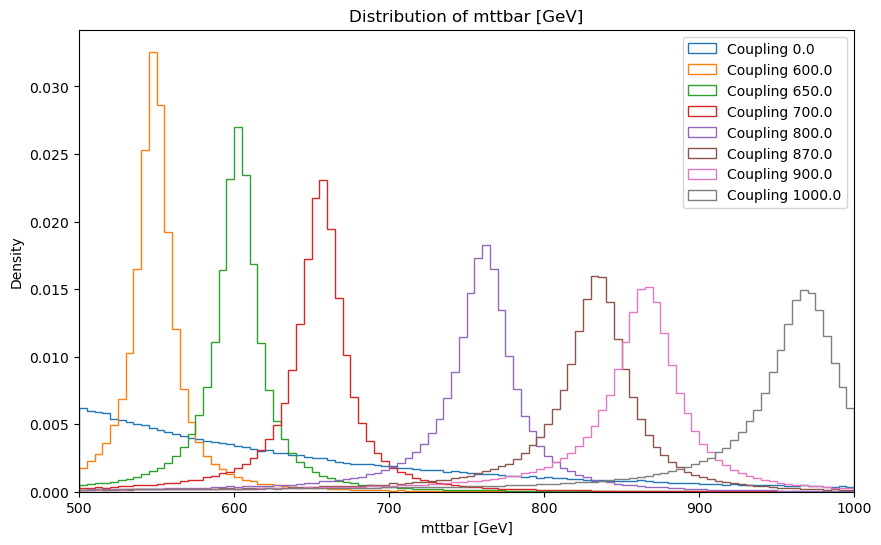

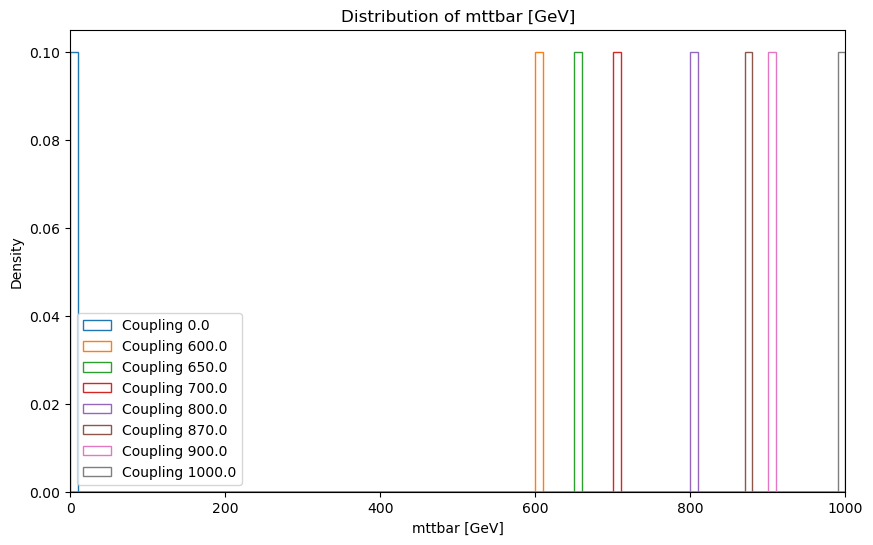

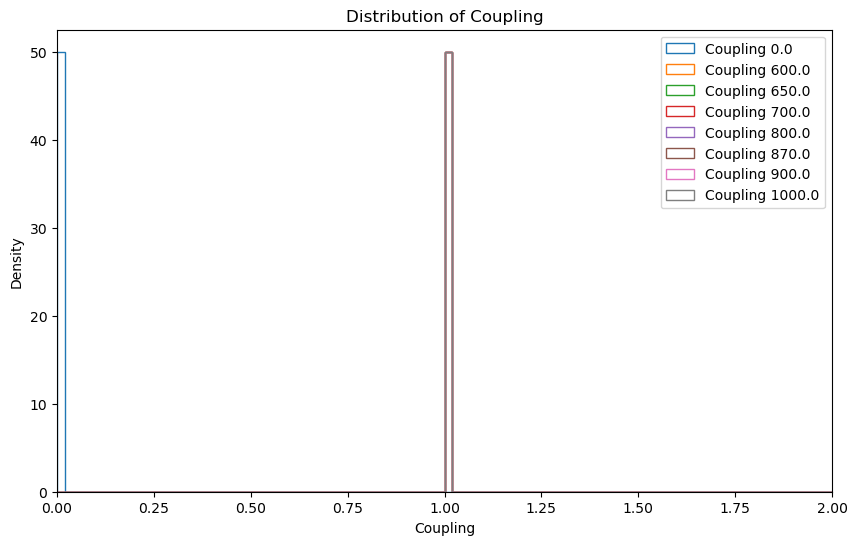

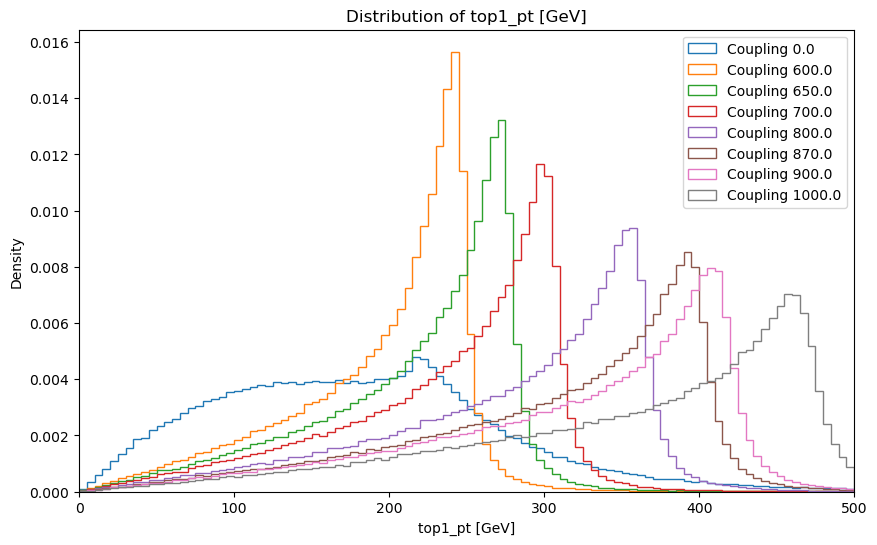

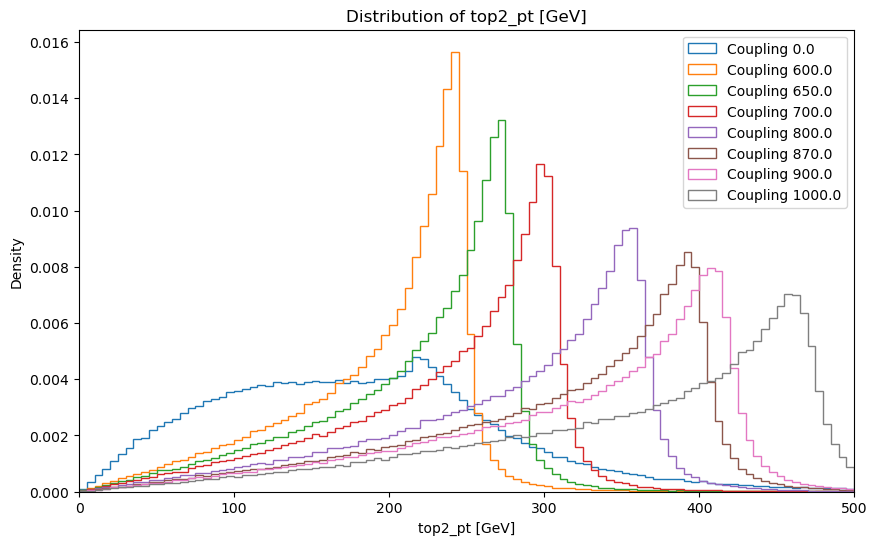

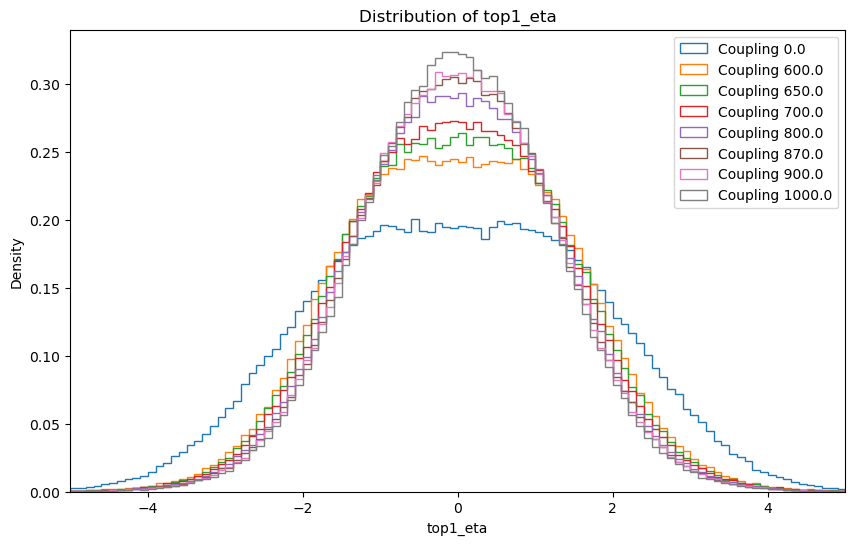

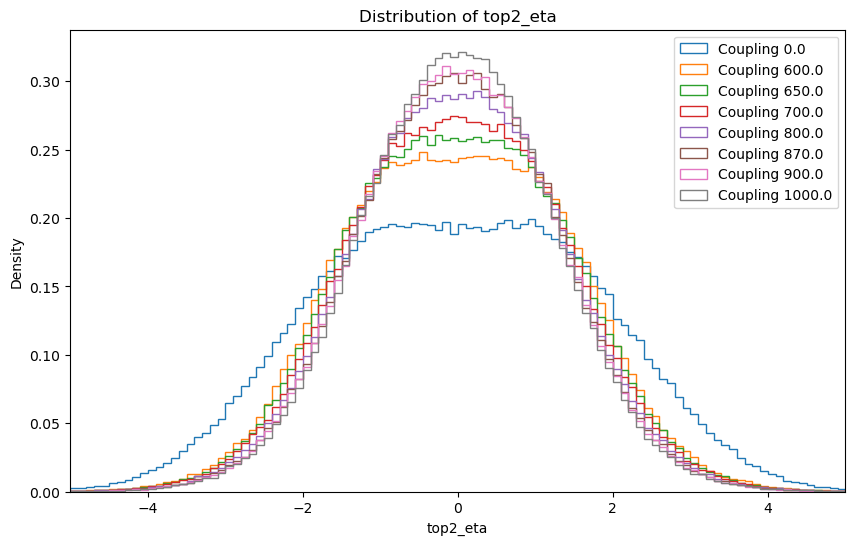

/home/dbaronmo/miniforge3/envs/vbf_ditau/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:895: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


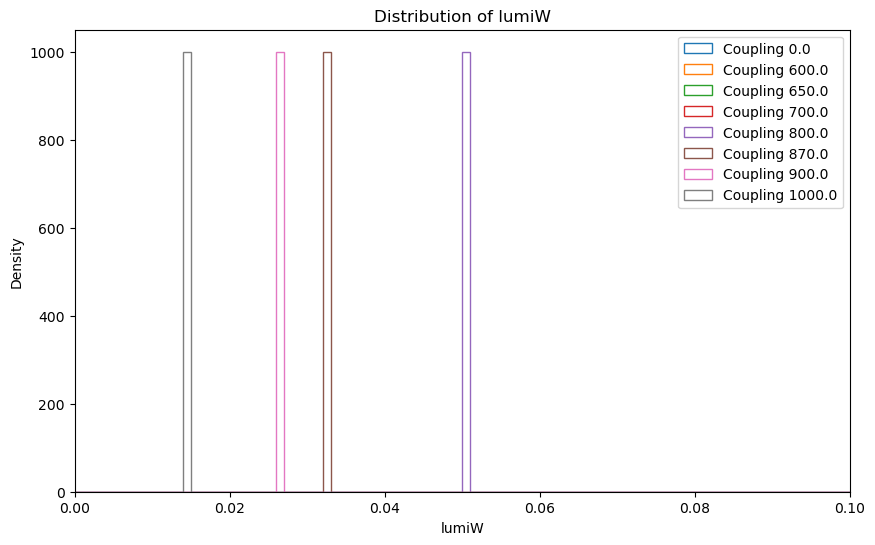

In [41]:
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], indices_per_coupling, x_range=[500,1000], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['hmass'][:], indices_per_coupling, x_range=[0,1000], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,0.1], variable_name='lumiW', n_bins=100)

In [42]:
def structure_data(data_file, coupling_values_for_training, training_indices) -> tuple[np.ndarray, np.ndarray, dict]:
    # Extract the features. 
    X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
    X = rfn.structured_to_unstructured(X)
    X, y = X[training_indices], y[training_indices]
    X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:][training_indices]
    X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['hmass'][:][training_indices]
    X_weights = data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:][training_indices]
    y_category = np.empty_like(y)
    couplings_category_dict = {}
    for i in range(len(coupling_values)):
        couplings_category_dict[float(coupling_values[i])] = i


    # Now fill the category array by loopoing over the X_couplings and assigning the category based on the coupling value
    for i in range(len(X_couplings)):
        coupling_value = X_couplings[i]
        category = couplings_category_dict[round(float(coupling_value), 1)]
        y_category[i] = category
        # Also if the coupling is category 0, give it the first coupling value for training, which is 0.2, later on we will augment the data with the other couplings
        if category == 0:
            X_couplings[i] = coupling_values_for_training[0]

    # Form the data
    X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1), X_weights.reshape(-1,1)], axis=1)
    y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

    return X, y, couplings_category_dict

def augment_data_for_background(X, y, coupling_values_for_training):
    # Now we want to augment the data, copying every background event giving it every possible coupling.
    background_indices = np.argwhere(y[:, 0] == 0).flatten()
    print("Augmenting data for background events. Number of background events to augment: ", len(background_indices))
    print("Number of augmentations per background event: ", len(coupling_values_for_training) - 1)
    augmented_X = []
    augmented_y = []
    for idx in background_indices:
        for coupling in coupling_values_for_training[1:]:
            new_X = X[idx].copy()
            new_X[-2] = coupling
            augmented_X.append(new_X)
            augmented_y.append(y[idx])

    X_ag = np.concatenate([X, augmented_X], axis=0)
    y_ag = np.concatenate([y, augmented_y], axis=0)

    return X_ag, y_ag

In [43]:
coupling_values_for_training = [600, 700, 800, 900, 1000]
X, y, couplings_category_dict = structure_data(data_file, coupling_values_for_training, training_indices)
print('Before augmentation:')
print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X, y = augment_data_for_background(X, y, coupling_values_for_training)
print('After augmentation:')
print('X shape = ',X.shape)
print('y shape = ',y.shape)


Before augmentation:
X shape =  (2400000, 9)
X example =  [ 2.3466739e+02  8.1430149e-01 -2.6250648e+00  2.3466739e+02
  4.5949781e-01  5.1652789e-01  5.3600854e+02  6.0000000e+02
  5.2450624e+00]
y shape =  (2400000, 2)
y example =  [0. 0.]
Augmenting data for background events. Number of background events to augment:  300000
Number of augmentations per background event:  4
After augmentation:
X shape =  (3600000, 9)
y shape =  (3600000, 2)


In [44]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [45]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', StandardScaler(), [6]),
    ('hmass', MinMaxScaler(), [7]),
    ('weights', 'passthrough', [8])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X)
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (3600000, 7)
X example after scaling =  [ 5.4581733  5.4581733  0.536886   0.3028169 -1.0278236  0.
  5.2450624]


# Separate the datasets for new observations

In [46]:
# Print the dictionary to help user steer the code
for key, values in couplings_category_dict.items():
    print(key, ' --> ', values)

0.0  -->  0
600.0  -->  1
650.0  -->  2
700.0  -->  3
800.0  -->  4
870.0  -->  5
900.0  -->  6
1000.0  -->  7


In [47]:
coupling_m650_indices = np.argwhere(y[:,1]==2)
coupling_m870_indices = np.argwhere(y[:,1]==5)

X_inference_1 = X[coupling_m650_indices]
X_inference_2 = X[coupling_m870_indices]
y_inference_1 = y[coupling_m650_indices]
y_inference_2 = y[coupling_m870_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_m650_indices, coupling_m870_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_m650_indices, coupling_m870_indices)), axis=0)

In [48]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (2400000, 7)
Validation set size =  (300000, 7)
Test set size =  (300000, 7)


In [49]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [50]:
import torch.nn as nn
# Define the Classifier
class RatioEstimator(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(RatioEstimator, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
            print("X dimension =", x_dim)
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
            print("X dimension =", x_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim//2, 1),
        )

    def forward(self, X, theta):
        model_input = torch.cat([X, theta], dim=1)
        logits = self.net(model_input)
        return logits
    
def norm_weights_per_batch(weights, categories):
    # Extract what categories are present in the batch
    unique_categories = torch.unique(categories)
    number_of_categories = len(unique_categories)
    # For each category, compute the sum of weights and normalize the weights in that category
    for category in unique_categories:
        category_mask = (categories == category)
        category_weights_sum = weights[category_mask].sum()
        if category_weights_sum > 0 and category!=0:
            weights[category_mask] = weights[category_mask] / (category_weights_sum * (number_of_categories-1))
        elif category_weights_sum > 0 and category==0:
            weights[category_mask] = weights[category_mask] / category_weights_sum
    return weights

In [51]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor,
                              y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,
                              y_val_tensor)
test_dataset  = TensorDataset(X_test_tensor,
                              y_test_tensor)

# Create DataLoader objects for training, validation, and testing in batches
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True, num_workers=8, persistent_workers=True, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=2048, shuffle=False, num_workers=8, persistent_workers=True, drop_last=True)
test_loader  = DataLoader(test_dataset, batch_size=2048, shuffle=False, num_workers=8)

In [52]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer_parametric = optim.AdamW(model.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler = ReduceLROnPlateau(optimizer_parametric, "min", patience=10, factor=0.8)

NN: Using parametric model with theta dimension = 1
X dimension = 5


In [53]:
import time
# Training loop on mini-batches with loss stored for plotting
train_losses = []
val_losses = []
num_epochs = 200
start_time = time.time()
model.to(device)

for epoch in range(num_epochs):
    epoch_start_time = time.time()
    model.train()
    # run over batches of data
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer_parametric.zero_grad()
        inputs_device = inputs.to(device)
        targets_device = targets[:,0].to(device)
        categories_device = targets[:,1].to(device)
        X = inputs_device[:,:-2]
        theta = inputs_device[:,-2].unsqueeze(1)
        outputs = model(X, theta)
        # outputs = torch.sigmoid(outputs)
        # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
        weights = inputs_device[:,-1]
        norm_weigths = norm_weights_per_batch(weights, categories_device)
        # Calculate the weighted loss
        loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
        loss = torch.sum(loss)
        loss.backward()
        optimizer_parametric.step()
        running_loss += loss.item()

    # compute avergae loss over all batches
    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation step
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            categories_device = targets[:,1].to(device)
            X = inputs_device[:,:-2]
            theta = inputs_device[:,-2].unsqueeze(1)
            outputs = model(X, theta)
            # outputs = torch.sigmoid(outputs)
            # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
            weights = inputs_device[:,-1]
            norm_weigths = norm_weights_per_batch(weights, categories_device)
            # Calculate the weighted loss
            loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
            loss = torch.sum(loss)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    scheduler.step(val_loss)

    current_time = time.time()
    print(f"Total Time: {round(current_time - start_time,1)}s, Epoch Time: {round(current_time - epoch_start_time,2)}s")
    print(f"Learning rate: {scheduler.get_last_lr()[0]}")
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

Total Time: 6.4s, Epoch Time: 6.38s
Learning rate: 0.0002
Epoch 1/200, Train Loss: 0.8868, Val Loss: 0.6997
Total Time: 11.7s, Epoch Time: 5.34s
Learning rate: 0.0002
Epoch 2/200, Train Loss: 0.6905, Val Loss: 0.6788
Total Time: 18.0s, Epoch Time: 6.29s
Learning rate: 0.0002
Epoch 3/200, Train Loss: 0.6819, Val Loss: 0.6755
Total Time: 24.0s, Epoch Time: 6.02s
Learning rate: 0.0002
Epoch 4/200, Train Loss: 0.6799, Val Loss: 0.6750
Total Time: 29.6s, Epoch Time: 5.52s
Learning rate: 0.0002
Epoch 5/200, Train Loss: 0.6788, Val Loss: 0.6744
Total Time: 35.7s, Epoch Time: 6.19s
Learning rate: 0.0002
Epoch 6/200, Train Loss: 0.6785, Val Loss: 0.6762
Total Time: 41.6s, Epoch Time: 5.89s
Learning rate: 0.0002
Epoch 7/200, Train Loss: 0.6777, Val Loss: 0.6736
Total Time: 47.4s, Epoch Time: 5.73s
Learning rate: 0.0002
Epoch 8/200, Train Loss: 0.6774, Val Loss: 0.6771
Total Time: 53.0s, Epoch Time: 5.62s
Learning rate: 0.0002
Epoch 9/200, Train Loss: 0.6773, Val Loss: 0.6740
Total Time: 59.1s, E

In [19]:
save_model = True
if save_model:
    print("Saving model...")
    torch.save(model.state_dict(), 'Mass_Inference_S_vs_BG.pth')

Saving model...


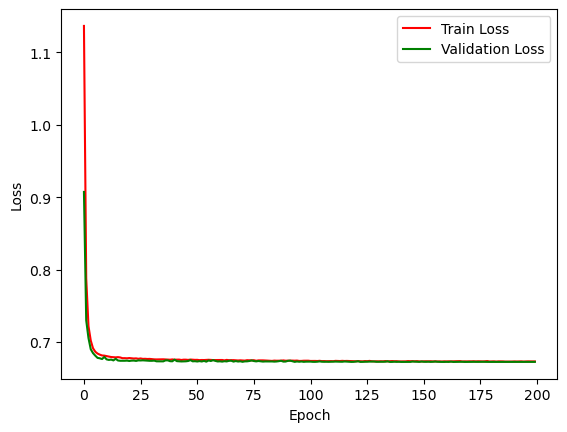

In [20]:
# Plot loss function for training and validation sets
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(val_losses, label='Validation Loss', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Loss', 'Validation Loss'])
plt.show()

NN: Using parametric model with theta dimension = 1
X dimension = 5


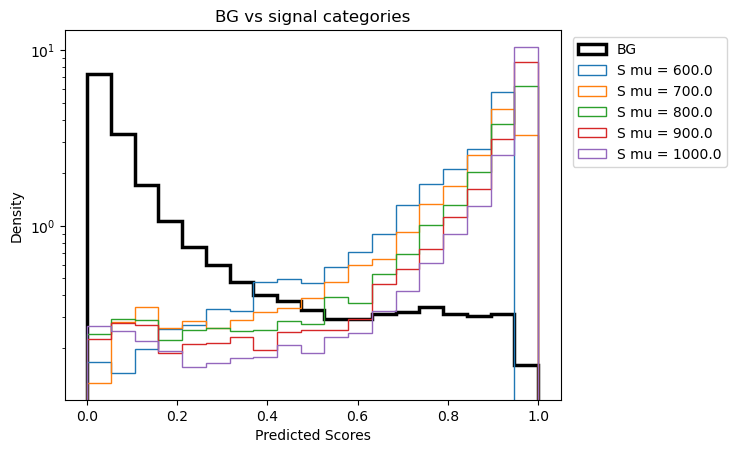

In [21]:
load_model = True
if load_model:
    eval_model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('Mass_Inference_S_vs_BG.pth', weights_only=True))
else:
    eval_model = model


eval_model.to('cpu')
eval_model.eval()
y_pred = torch.sigmoid(eval_model(X_test_tensor[:,:-2], X_test_tensor[:,-2].unsqueeze(1)).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test[:,0]
category_label = y_test[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = set(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

x_bins = np.linspace(0,1,20)

plt.hist(true_bkg, bins=x_bins, histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=x_bins, histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

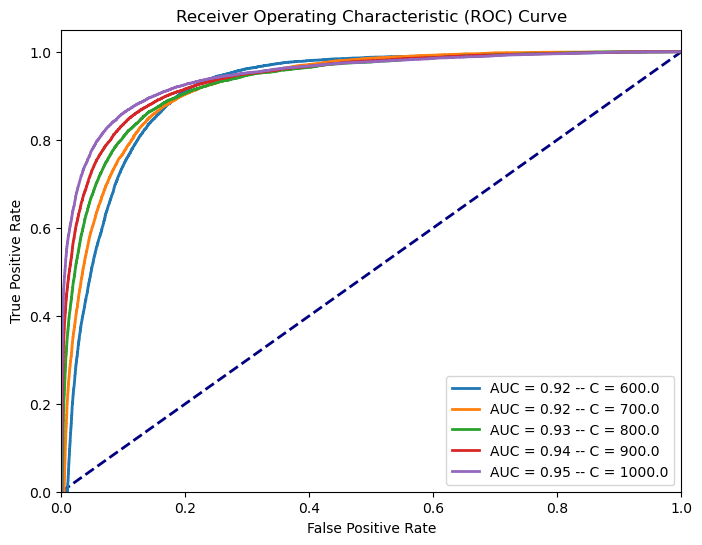

In [22]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [31]:
def Logits(x_obs, theta):
    logits = eval_model(x_obs, theta)
    logits = logits.reshape(-1)
    return logits

def log_likelihood(theta, X_obs, weights):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    llh = Logits(X_obs, thetas)
    return torch.sum(weights*llh)


def log_likelihood_ratio(theta, X_obs, weights):
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    logits = Logits(X_obs, thetas)
    scores = torch.sigmoid(logits)
    llh_ratio = scores / (1-scores)
    log_llh_ratio = torch.log(llh_ratio)
    return torch.sum(weights*log_llh_ratio)

def corrected_log_likelihood(theta, X_obs, weights, X_ref, w_ref):

    N = X_obs.shape[0]
    theta_expand = theta.expand(N,1)

    logits = eval_model(X_obs, theta_expand)

    # compute normalization constant
    theta_ref_expand = theta.expand(X_ref.shape[0],1)
    logits_ref = eval_model(X_ref, theta_ref_expand)
    r_ref = torch.exp(logits_ref)

    K = (w_ref * r_ref).sum() / w_ref.sum()

    return torch.sum(weights * logits) - weights.sum() * torch.log(K)

def check_ratio(theta_value, X_ref, weights_ref, eval_model):

    N = X_ref.shape[0]
    X_ref = torch.tensor(X_ref, dtype=torch.float32)
    theta = theta_value.expand(N, 1)

    with torch.no_grad():
        logits = eval_model(X_ref, theta)

    r = torch.exp(logits).reshape(-1)

    weights_ref = torch.tensor(weights_ref, dtype=torch.float32)
    return (weights_ref * r).sum() / weights_ref.sum()

def parameter_inference(theta_scan, X_obs, weights):
    log_likelihoods = []
    
    for itheta in theta_scan:
        theta_transformed = scaler["hmass"].transform([[itheta]])[0,0]
        print("Scanning theta = ", round(theta_transformed, 2))
        theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
        # llh = corrected_log_likelihood(theta_tensor, new_X, weights, X_ref, weights_ref)
        llh = log_likelihood(theta_tensor, X_obs, weights)
        log_likelihoods.append(llh.item())

    max_llh = np.array(max(log_likelihoods))
    q_mu = -2*(log_likelihoods - max_llh)

    plt.plot(theta_scan, q_mu)
    plt.xlabel("Theta")
    plt.ylabel("q_mu")
    plt.xlim((min(theta_scan),max(theta_scan)))
    plt.show()

    # Get the MLE estimate for theta
    np.argmin(q_mu)
    theta_mle = theta_scan[np.argmin(q_mu)]
    print("MLE estimate for theta:", theta_mle)

    return theta_mle, q_mu

def alternative_parameter_inference(theta_scan, X_obs, weights):
    log_likelihoods = []
    
    for itheta in theta_scan:
        theta_transformed = scaler["hmass"].transform([[itheta]])[0,0]
        print("Scanning theta = ", round(theta_transformed, 2))
        theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
        # llh = corrected_log_likelihood(theta_tensor, new_X, weights, X_ref, weights_ref)
        llh = log_likelihood_ratio(theta_tensor, X_obs, weights)
        log_likelihoods.append(llh.item())

    max_llh = np.array(max(log_likelihoods))
    q_mu = -2*(log_likelihoods - max_llh)

    plt.plot(theta_scan, q_mu)
    plt.xlabel("Theta")
    plt.ylabel("q_mu")
    plt.xlim((min(theta_scan),max(theta_scan)))
    plt.show()

    # Get the MLE estimate for theta
    np.argmin(q_mu)
    theta_mle = theta_scan[np.argmin(q_mu)]
    print("MLE estimate for theta:", theta_mle)

    return theta_mle, q_mu
    
    

In [32]:
bg_test_mask = y_test[:,0] == 0
X_bg_test, y_bg_test = X_test[bg_test_mask], y_test[bg_test_mask]

X_bg_test_ref = X_bg_test[:,:-2]
w_bg_ref = X_bg_test[:,-1]

print(check_ratio(torch.tensor(0.2), X_bg_test_ref, w_bg_ref, eval_model))
print(check_ratio(torch.tensor(0.4), X_bg_test_ref, w_bg_ref, eval_model))
print(check_ratio(torch.tensor(0.9), X_bg_test_ref, w_bg_ref, eval_model))

tensor(1.0113)
tensor(0.9918)
tensor(1.0012)


Scanning theta =  -0.25
I am being called...
Scanning theta =  -0.22
I am being called...
Scanning theta =  -0.19
I am being called...
Scanning theta =  -0.16
I am being called...
Scanning theta =  -0.13
I am being called...
Scanning theta =  -0.1
I am being called...
Scanning theta =  -0.07
I am being called...
Scanning theta =  -0.04
I am being called...
Scanning theta =  -0.01
I am being called...
Scanning theta =  0.03
I am being called...
Scanning theta =  0.06
I am being called...
Scanning theta =  0.09
I am being called...
Scanning theta =  0.12
I am being called...
Scanning theta =  0.15
I am being called...
Scanning theta =  0.18
I am being called...
Scanning theta =  0.21
I am being called...
Scanning theta =  0.24
I am being called...
Scanning theta =  0.27
I am being called...
Scanning theta =  0.3
I am being called...
Scanning theta =  0.33
I am being called...
Scanning theta =  0.36
I am being called...
Scanning theta =  0.39
I am being called...
Scanning theta =  0.42
I 

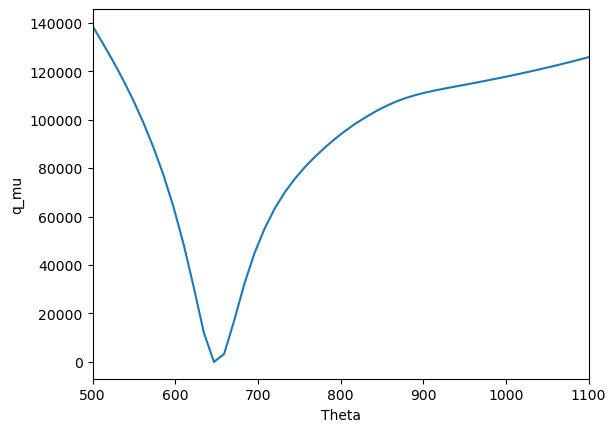

MLE estimate for theta: 646.9387755102041


In [33]:
new_data =  X_inference_1
new_data = new_data.reshape(-1, new_data.shape[2])
weights = torch.tensor(new_data[:,-1], requires_grad=False, dtype=torch.float32)
new_data = new_data[:,:-2] # Remove weight and coupling column
new_X = torch.tensor(new_data, requires_grad=False, dtype=torch.float32)

theta_scan = np.linspace(500,1100,50)
theta_mle, q_mu = alternative_parameter_inference(theta_scan, new_X, weights)

Scanning theta =  -0.25
I am being called...
Scanning theta =  -0.22
I am being called...
Scanning theta =  -0.19
I am being called...
Scanning theta =  -0.16
I am being called...
Scanning theta =  -0.13
I am being called...
Scanning theta =  -0.1
I am being called...
Scanning theta =  -0.07
I am being called...
Scanning theta =  -0.04
I am being called...
Scanning theta =  -0.01
I am being called...
Scanning theta =  0.03
I am being called...
Scanning theta =  0.06
I am being called...
Scanning theta =  0.09
I am being called...
Scanning theta =  0.12
I am being called...
Scanning theta =  0.15
I am being called...
Scanning theta =  0.18
I am being called...
Scanning theta =  0.21
I am being called...
Scanning theta =  0.24
I am being called...
Scanning theta =  0.27
I am being called...
Scanning theta =  0.3
I am being called...
Scanning theta =  0.33
I am being called...
Scanning theta =  0.36
I am being called...
Scanning theta =  0.39
I am being called...
Scanning theta =  0.42
I 

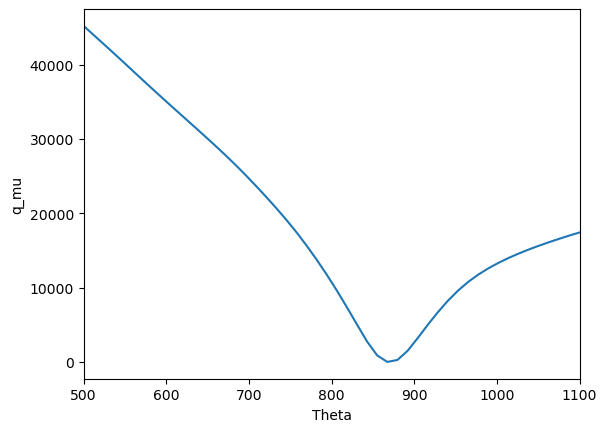

MLE estimate for theta: 867.3469387755101


In [34]:
new_data =  X_inference_2
new_data = new_data.reshape(-1, new_data.shape[2])
weights = torch.tensor(new_data[:,-1], requires_grad=False, dtype=torch.float32)
new_data = new_data[:,:-2] # Remove weight and coupling column
new_X = torch.tensor(new_data, requires_grad=False, dtype=torch.float32)

theta_scan = np.linspace(500,1100,50)
theta_mle, q_mu = alternative_parameter_inference(theta_scan, new_X, weights)

Scanning theta =  -0.25
I am being called...
Scanning theta =  -0.22
I am being called...
Scanning theta =  -0.19
I am being called...
Scanning theta =  -0.16
I am being called...
Scanning theta =  -0.13
I am being called...
Scanning theta =  -0.1
I am being called...
Scanning theta =  -0.07
I am being called...
Scanning theta =  -0.04
I am being called...
Scanning theta =  -0.01
I am being called...
Scanning theta =  0.03
I am being called...
Scanning theta =  0.06
I am being called...
Scanning theta =  0.09
I am being called...
Scanning theta =  0.12
I am being called...
Scanning theta =  0.15
I am being called...
Scanning theta =  0.18
I am being called...
Scanning theta =  0.21
I am being called...
Scanning theta =  0.24
I am being called...
Scanning theta =  0.27
I am being called...
Scanning theta =  0.3
I am being called...
Scanning theta =  0.33
I am being called...
Scanning theta =  0.36
I am being called...
Scanning theta =  0.39
I am being called...
Scanning theta =  0.42
I 

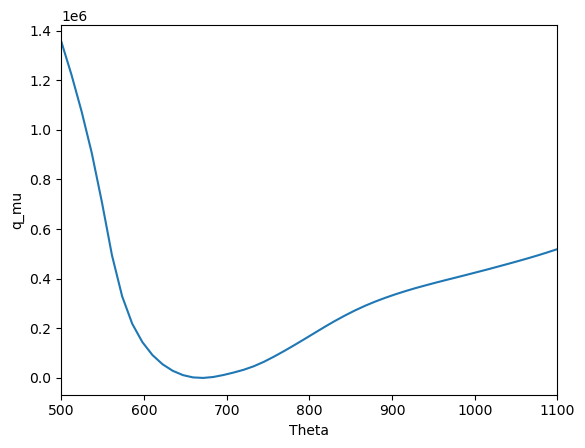

MLE estimate for theta: 671.4285714285714
Scanning theta =  -0.25
I am being called...
Scanning theta =  -0.22
I am being called...
Scanning theta =  -0.19
I am being called...
Scanning theta =  -0.16
I am being called...
Scanning theta =  -0.13
I am being called...
Scanning theta =  -0.1
I am being called...
Scanning theta =  -0.07
I am being called...
Scanning theta =  -0.04
I am being called...
Scanning theta =  -0.01
I am being called...
Scanning theta =  0.03
I am being called...
Scanning theta =  0.06
I am being called...
Scanning theta =  0.09
I am being called...
Scanning theta =  0.12
I am being called...
Scanning theta =  0.15
I am being called...
Scanning theta =  0.18
I am being called...
Scanning theta =  0.21
I am being called...
Scanning theta =  0.24
I am being called...
Scanning theta =  0.27
I am being called...
Scanning theta =  0.3
I am being called...
Scanning theta =  0.33
I am being called...
Scanning theta =  0.36
I am being called...
Scanning theta =  0.39
I am

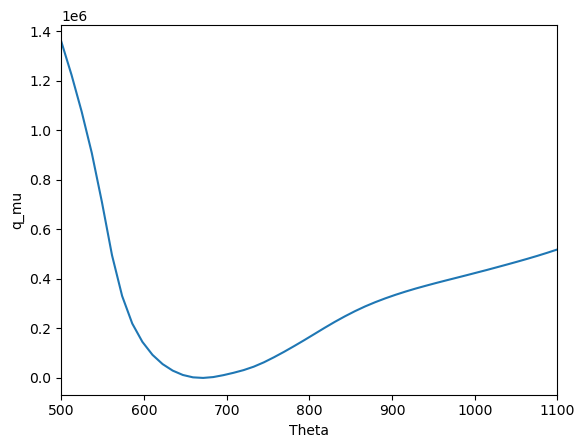

MLE estimate for theta: 671.4285714285714


In [35]:
bg_test_mask = y_test[:,0] == 0
sig_test_mask = y_test[:,1] == 4
X_bg_test, y_bg_test = X_test[bg_test_mask], y_test[bg_test_mask]
X_sig_test, y_sig_test = X_test[sig_test_mask], y_test[sig_test_mask]

X_bg_test_ref = X_bg_test[:,:-2]
X_sig_test_ref = X_sig_test[:,:-2]
w_bg_ref = X_bg_test[:,-1]
w_sig_ref = X_sig_test[:,-1]




new_data =  np.concatenate([X_bg_test_ref, X_sig_test_ref], axis=0)
weights = np.concatenate([w_bg_ref, w_sig_ref], axis=0)
weights_data = torch.tensor(weights, requires_grad=False, dtype=torch.float32)
new_X = torch.tensor(new_data, requires_grad=False, dtype=torch.float32)

theta_scan = np.linspace(500,1100,50)

theta_mle_bg, q_mu_bg = alternative_parameter_inference(theta_scan, torch.tensor(X_bg_test_ref,dtype=torch.float32), torch.tensor(w_bg_ref,dtype=torch.float32))
theta_mle, q_mu = alternative_parameter_inference(theta_scan, new_X, weights_data)

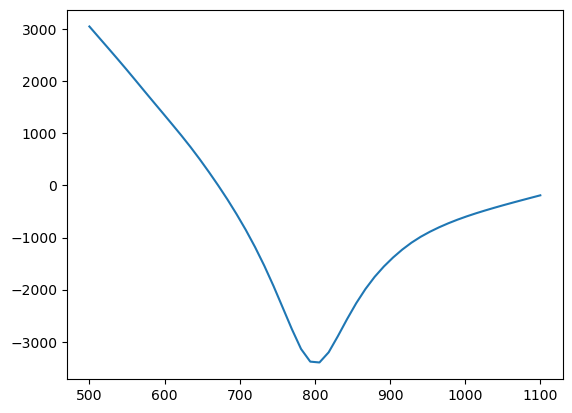

In [36]:
plt.plot(theta_scan, q_mu - q_mu_bg)